# Figure 5 (K=3, corrected labels) on the relaxed IR bed

Same page as `Figure5_publication_K3_corrected`, except panel C comes from
`AD_IR_only_plots.relaxed.bed.gz`: a torino exon only has to fall within the
**body of the gene**, not within the span of the APPRIS-principal transcript.

Everything is drawn by `Figure5_publication`; this notebook selects the
`k3_corrected_relaxed` version and reports what the relaxation buys.

In [1]:
import os
import sys

import pandas as pd
from matplotlib import pyplot as plt

FIG5_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/Figure5'
ANALYSIS_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/analysis'
os.chdir(ANALYSIS_DIR)
if FIG5_DIR not in sys.path:
    sys.path.append(FIG5_DIR)

import Figure5_helpers as H
import Figure5_plot_helpers as PH
import Figure5_publication as P

d = P.load_panels()
print('version:', P.VERSIONS['k3_corrected_relaxed'])

version: {'twas': 'twas_panel_k3', 'knop1_k': 3, 'pooled': True, 'ir': 'ir_panel_k3_relaxed_sig_colocK3', 'beta': 'k3_beta_stats_fdr0p1'}


## What the relaxation changes

The strict containment test discards torino exons outside a short APPRIS
transcript, which can leave a gene with no IR interval at all — MRPL43 is the
case it was written for.

In [2]:
# Panel C, in two steps away from the strict bed.
#
# 1. Relaxed containment. The strict bed tests each torino exon with `f=1`
#    against the span of the APPRIS-principal transcript; when that transcript
#    is a short isoform the exons outside it are discarded and the gene can end
#    up with no IR interval at all. MRPL43 is the case: a 1.2 kb APPRIS span
#    against a 17.8 kb torino isoform. The relaxed bed contains the gene body
#    instead, 2,940 -> 3,225 genes.
#
# 2. Significance. Neither bed filtered on the logistic regression at all --
#    the gene set was an annotation filter, 3,908 genes carrying an IR-only
#    factor of which only 1,082 reach FDR 0.1. The bed this figure uses applies
#    that cut, and panel A's significance cut moves to 0.1 to match.
strict = d['ir_panel_k3_colocK3']
relaxed = d['ir_panel_k3_relaxed_colocK3']
drawn = d[P.VERSIONS['k3_corrected_relaxed']['ir']]
sym = H.load_k3_gene_symbols()

for tag, panel in [('strict        ', strict),
                   ('relaxed       ', relaxed),
                   ('relaxed + FDR ', drawn)]:
    names = sorted(panel['gene_names'].get(g, g) for g in panel['gene_label'])
    print(f'{tag} {len(panel["order_df"]):5d} genes | labelled {len(names)}: {names}')
print('\n^ the last row is what this figure draws')

# Panel A, at the same FDR.
b = d[P.VERSIONS['k3_corrected_relaxed']['beta']]
print(f"\npanel A at FDR {b['fdr']}:")
print(f"   No IR  {b['si_pos_ratio'] * 100:5.1f}% increasing in AD  (n={b['total_si']})")
print(f"   IR     {b['ir_pos_ratio'] * 100:5.1f}% increasing in AD  (n={b['total_ir']})")

# Of the 18 ir_ad_factor genes, which the heatmap can still show.
tbl = d['k3_coloc_table']
g18 = list(dict.fromkeys(tbl.loc[tbl.ir_ad_factor].gene_id))
absent = [sym.get(g, g) for g in g18 if g not in set(drawn['order_df'].gene)]
print(f'\nof the 18 colocalisation genes, {len(g18) - len(absent)} are labelled; '
      f'{len(absent)} are absent:')
print(f'   {absent}')

strict          2940 genes | labelled 3: ['EGFR', 'KNOP1', 'TSPAN14']
relaxed         3225 genes | labelled 4: ['EGFR', 'KNOP1', 'MRPL43', 'TSPAN14']
relaxed + FDR    876 genes | labelled 2: ['KNOP1', 'MRPL43']

^ the last row is what this figure draws

panel A at FDR 0.1:
   No IR   32.2% increasing in AD  (n=947)
   IR      97.4% increasing in AD  (n=2704)

of the 18 colocalisation genes, 2 are labelled; 16 are absent:
   ['TSPAN14', 'SLC39A13', 'DNAL1', 'YPEL3', 'GPRC5B', 'C17orf100', 'REXO1', 'KLF16', 'ZNF638', 'ITGB1BP1', 'SIRPA', 'RNF185', 'DCAF16', 'CPLX1', 'THSD7A', 'EGFR']


## The figure

Saved as `Figure5_publication_K3_corrected_relaxed.png` / `.pdf` / `.svg`.

page: 180.0 x 252.1 mm  ->  Figure5_publication_K3_corrected_relaxed.png / .pdf / .svg


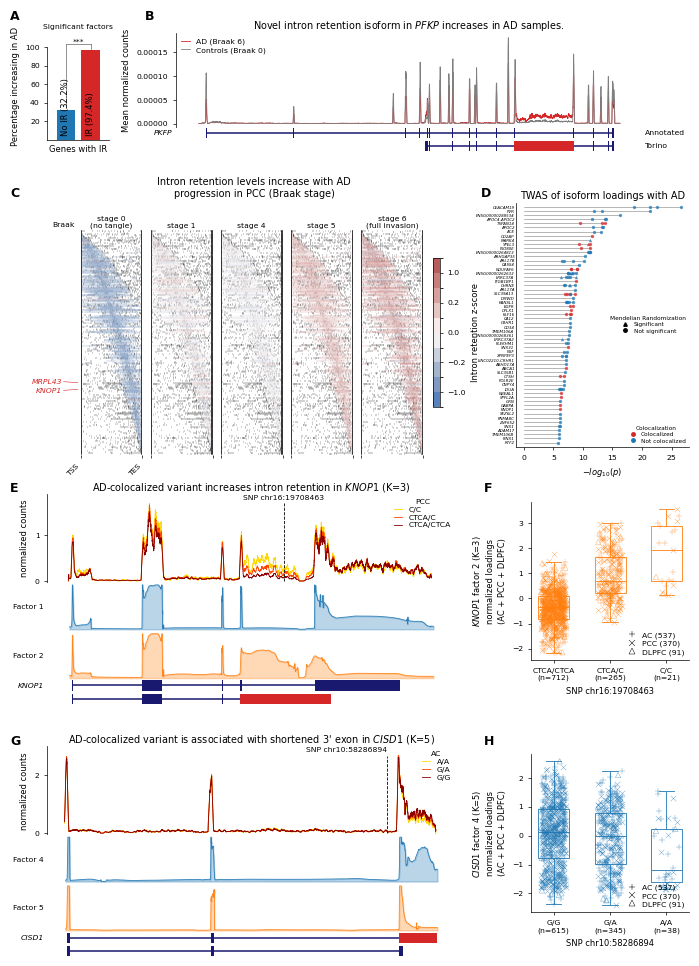

In [3]:
fig = P.save(P.build_figure(d, version='k3_corrected_relaxed'),
             'Figure5_publication_K3_corrected_relaxed')
print(f'page: {P.PAGE_W:.1f} x {P.PAGE_H:.1f} mm  ->  '
      f'Figure5_publication_K3_corrected_relaxed.png / .pdf / .svg')

## Supplementary: UTR3_changes

Rebuilt from the new 3' UTR logistic regression
(`scripts/prepare_ad_utr3_logreg.py`), which uses the `AD_K3_LR` covariate set.
K=5 throughout, including a different colocalisation table from panel C's.

source           : /project2/yangili1/cfbuenabadn/torino_paper/code/results/gao_k5/tables/UTR3.logreg.output.tab.gz
regression rows  : 4709  (FDR<=0.05: 274, FDR<=0.1: 422)
gene threshold   : FDR <= 0.1
matrix           : 295 genes x 6 condition-tissue groups
labelled (K=5 coloc): ['ATP6V1C1', 'CISD1']

CISD1, the gene panels G/H show:
                                   beta     pval  pval_fdr
feature                                                   
ENSG00000122873_rank0_isoform_4  0.1399 0.007636   0.09015
ENSG00000122873_rank1_isoform_1  -0.113  0.07968    0.3401
ENSG00000122873_rank2_isoform_2 0.02856   0.6169    0.8572



saved UTR3_changes.pdf / .png / .svg


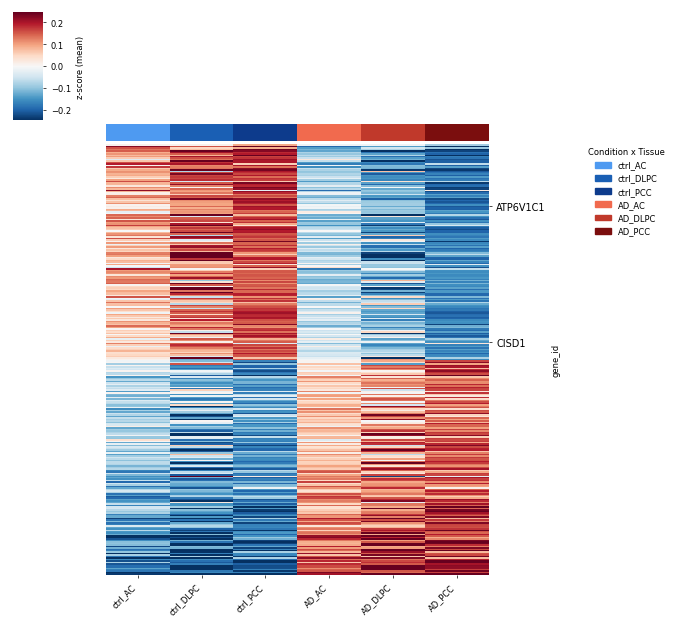

In [4]:
# Supplementary: UTR3_changes, rebuilt from the new 3' UTR logistic regression.
#
# The usage matrix is the terminal-exon grouping of AD_UTR.ipynb (factors merged
# by 3' UTR position, efficiency factors removed at isoform selection, loadings
# renormalised per sample to sum to 1 within each UTR start and then collapsed
# per length rank). What changed is the regression on top: it now uses the
# AD_K3_LR covariate set
#   tissue_id, batch, msex, race_string, spanish, age_group, log10PMI, RIN
# rather than the notebook's tissue_id/batch/msex/race.
#
# This panel is K=5 end to end -- snmf5_EL, the gao isoform annotation, and the
# genome-wide K=5 colocalisation table for the row labels. That is a different
# coloc file from panel C's gao_k3 colocboost summary.
# Genes enter at FDR <= 0.1, the cut panels A and C use. The wider covariate
# set costs power against the notebook's four covariates -- CISD1's leading UTR
# rank moves from FDR 0.026 to 0.090 on a near-identical beta (0.146 -> 0.140) --
# so 0.05 would have dropped genes for want of precision rather than effect.
utr3 = d['utr3_panel_newlr']
res = utr3['res']
print(f"source           : {utr3['source']}")
print(f"regression rows  : {len(res)}  "
      f"(FDR<=0.05: {int((res.pval_fdr <= 0.05).sum())}, "
      f"FDR<=0.1: {int((res.pval_fdr <= 0.1).sum())})")
print(f"gene threshold   : FDR <= {utr3['pval_thresh']}")
print(f"matrix           : {utr3['el_means'].shape[0]} genes x "
      f"{utr3['el_means'].shape[1]} condition-tissue groups")
print(f"labelled (K=5 coloc): {utr3['label_names']}")

_cisd1 = res.loc[res.index.str.startswith('ENSG00000122873')]
print('\nCISD1, the gene panels G/H show:')
print(_cisd1[['beta', 'pval', 'pval_fdr']].to_string(
    float_format=lambda v: f'{v:.4g}'))

g = PH.plot_utr3_changes(utr3)
for _ext in ('pdf', 'png', 'svg'):
    g.savefig(os.path.join(FIG5_DIR, f'UTR3_changes.{_ext}'),
              dpi=400 if _ext == 'png' else None, bbox_inches='tight')
print('\nsaved UTR3_changes.pdf / .png / .svg')

## Boxplot statistics

F and H carry no annotation: the two-line note needed 26% headroom and squashed
the boxes, so the fits are printed here and added to the figure by hand.

               panel                         model    beta     se          pval   n     r2
KNOP1 factor 2 (K=3) OLS usage ~ genotype + tissue  1.2209 0.0484 5.407347e-109 998 0.3911
CISD1 factor 4 (K=5) OLS usage ~ genotype + tissue -0.2326 0.0615  1.658453e-04 998 0.0145


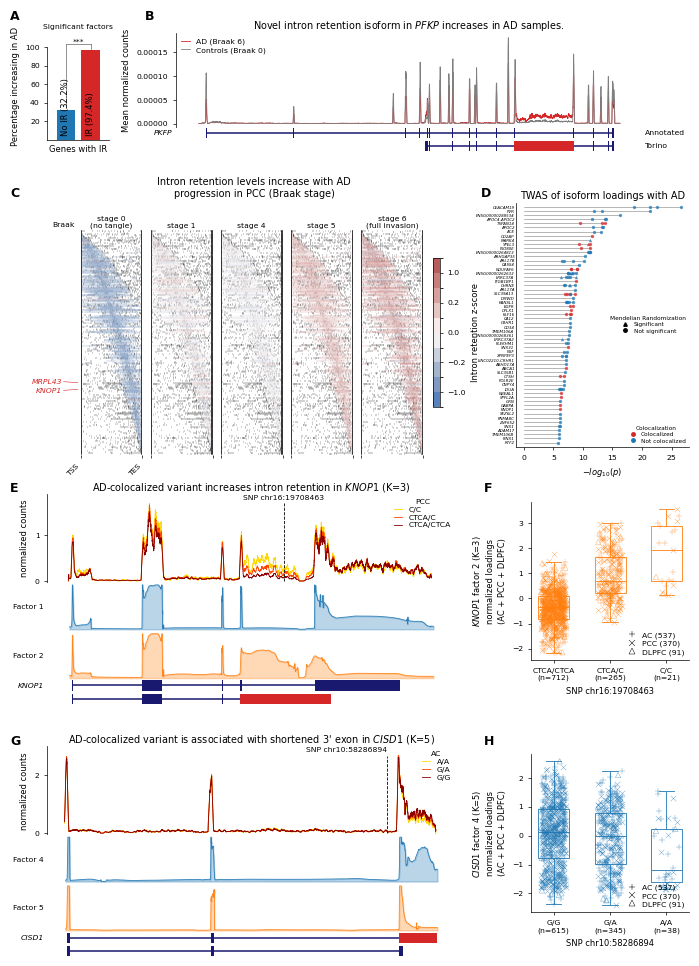

In [5]:
# The boxplot fits, printed rather than drawn: the two-line note on each panel
# needed 26% headroom and squashed the boxes, so F and H carry no annotation and
# these are added to the figure by hand.
print(P.report_regressions(fig).to_string(index=False))

fig

## The 3' UTR numbers

Counts for the methods text, old covariates against new. Computed here rather
than transcribed, so they follow the tables they are read from.

In [6]:
# The 3' UTR counts, old covariates against new.
#
# "old" is the cached notebook regression (tissue, batch, sex, race) at FDR 0.05;
# "new" is scripts/prepare_ad_utr3_logreg.py (the AD_K3_LR covariate set) at the
# FDR 0.1 this figure uses. utr3_direction_summary does the counting: a gene
# contributes a direction only when its most significant UTR rank is the
# shortest or the longest, and a negative effective_beta is a shift toward the
# short 3' UTR.
import pickle
from IPython.display import Markdown, display

with open(os.path.join(FIG5_DIR, 'figure_data', 'utr_res.pkl'), 'rb') as fh:
    res_old = pickle.load(fh)
res_new = utr3['res']

counts = pd.DataFrame([
    H.utr3_direction_summary(res_old, 0.05, 'old: notebook covariates'),
    H.utr3_direction_summary(res_new, 0.10, 'new: AD_K3_LR covariates'),
]).set_index('analysis')
print(counts.T.to_string())

rows = [
    ('genes with >=2 polyA sites', 'genes_2plus_polyA', '{:,}'),
    ("3' UTR groups",              'utr_sites',         '{:,}'),
    ('significant sites',          'sig_sites',         '{:,}'),
    ('... in genes',               'sig_genes',         '{:,}'),
    ('genes with a usable shift',  'genes_with_shift',  '{:,}'),
]
md = ["| | old (notebook covariates, FDR 0.05) | new (AD_K3_LR covariates, FDR 0.1) |",
      "|---|---|---|"]
for name, key, fmt in rows:
    # the frame holds mixed types, so the counts come back as floats
    md.append(f"| {name} | {fmt.format(int(counts.iloc[0][key]))} | "
              f"{fmt.format(int(counts.iloc[1][key]))} |")
for name, n, pct in [("&rarr; short 3' UTR", 'short', 'short_pct'),
                     ("&rarr; long 3' UTR", 'long', 'long_pct')]:
    md.append(f"| {name} | {int(counts.iloc[0][n]):,} "
              f"(**{counts.iloc[0][pct]:.0f}%**) | "
              f"{int(counts.iloc[1][n]):,} (**{counts.iloc[1][pct]:.0f}%**) |")
utr3_counts_md = '\n'.join(md)
display(Markdown(utr3_counts_md))

analysis               old: notebook covariates  new: AD_K3_LR covariates
fdr                                        0.05                       0.1
genes_2plus_polyA                       2207.00                    2207.0
utr_sites                               4709.00                    4709.0
median_sites_per_gene                      2.00                       2.0
max_sites_per_gene                         5.00                       5.0
sig_sites                                588.00                     422.0
sig_genes                                427.00                     308.0
genes_with_shift                         412.00                     295.0
short                                    247.00                     148.0
short_pct                                 60.00                      50.0
long                                     165.00                     147.0
long_pct                                  40.00                      50.0


| | old (notebook covariates, FDR 0.05) | new (AD_K3_LR covariates, FDR 0.1) |
|---|---|---|
| genes with >=2 polyA sites | 2,207 | 2,207 |
| 3' UTR groups | 4,709 | 4,709 |
| significant sites | 588 | 422 |
| ... in genes | 427 | 308 |
| genes with a usable shift | 412 | 295 |
| &rarr; short 3' UTR | 247 (**60%**) | 148 (**50%**) |
| &rarr; long 3' UTR | 165 (**40%**) | 147 (**50%**) |

### Which covariate costs the asymmetry

Each row refits all 4,709 UTR groups at FDR 0.05, so the rows differ only in
the adjustment. **This cell takes a couple of minutes.**

In [7]:
# Which covariate costs the asymmetry. Each row refits all 4,709 UTR groups, so
# this cell takes a couple of minutes; FDR 0.05 throughout, so the rows differ
# only in the adjustment.
BASE = ['tissue_id', 'batch', 'msex', 'race']
FULL = ['tissue_id', 'batch', 'msex', 'race_string', 'spanish',
        'age_group', 'log10PMI', 'RIN']

sweep = H.utr3_covariate_sweep({
    'notebook 4':             BASE,
    '+ RIN only':             BASE + ['RIN'],
    '+ everything except RIN': [c for c in FULL if c != 'RIN'],
    'all 8':                  FULL,
}, pval_thresh=0.05)
print(sweep[['analysis', 'n_covariates', 'sig_sites', 'genes_with_shift',
             'short', 'short_pct']].to_string(index=False))

md = ["| covariates | significant sites | short |", "|---|---|---|"]
for _, r in sweep.iterrows():
    md.append(f"| {r['analysis']} | {int(r['sig_sites']):,} | "
              f"{r['short_pct']:.0f}% |")
utr3_sweep_md = '\n'.join(md)
display(Markdown(utr3_sweep_md))

print('\nDirection is not what changes: on the genes significant in both, the '
      'shift direction agrees and the effect sizes correlate closely. What '
      'moves the split is which genes fall below significance.')

/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Logistic regression failed for ENSG00000077684_rank0_isoform_1: did not converge, falling back to Mann-Whitney
Logistic regression failed for ENSG00000077684_rank1_isoform_3: did not converge, falling back to Mann-Whitney


/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.wa

Logistic regression failed for ENSG00000112701_rank0_isoform_4: did not converge, falling back to Mann-Whitney
Logistic regression failed for ENSG00000112701_rank1_isoform_3: did not converge, falling back to Mann-Whitney
Logistic regression failed for ENSG00000113300_rank0_isoform_3: did not converge, falling back to Mann-Whitney
Logistic regression failed for ENSG00000113300_rank1_isoform_2: did not converge, falling back to Mann-Whitney


/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.wa

...

/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:2443: RuntimeWarning: divide by zero encountered in log
  return np.sum(np.log(self.cdf(q * linpred)))
/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Logistic regression failed for ENSG00000213366_rank1_isoform_1: did not converge, falling back to Mann-Whitney


               analysis  n_covariates  sig_sites  genes_with_shift  short  short_pct
             notebook 4             4        588               412    247       60.0
             + RIN only             5        329               232    129       56.0
+ everything except RIN             7        542               382    211       55.0
                  all 8             8        274               195    100       51.0


| covariates | significant sites | short |
|---|---|---|
| notebook 4 | 588 | 60% |
| + RIN only | 329 | 56% |
| + everything except RIN | 542 | 55% |
| all 8 | 274 | 51% |


Direction is not what changes: on the genes significant in both, the shift direction agrees and the effect sizes correlate closely. What moves the split is which genes fall below significance.
